# Solution for Lab Activity 05

Feature Selection, Cross-Validation, and Model Complexity

Note: For many of the questions in this lab, there are multiple ways to answer the questions, and some of the answers you get will depend on the random seed you choose. The goal of this lab was not necessarily to drive you to a single answer, but to have you think through various situations where the right answer is not clear cut, and provide reasoned justifications for your answers. 

## Setup

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, SplineTransformer, StandardScaler

SCORING = "neg_root_mean_squared_error"

# Note: Reading in the Auto dataset as explicitly listed in the Data Preprocessing Notes for Part 1
auto = pd.read_csv("../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)
bike = pd.read_csv("../../data/bike-sharing-daily.csv")
auto.shape  # expect (392, 9)

(392, 9)

## Part 1: Feature Selection

### Q1a: Data Preprocessing and exploration 

cylinders
4    199
8    103
6     83
3      4
5      3
Name: count, dtype: int64


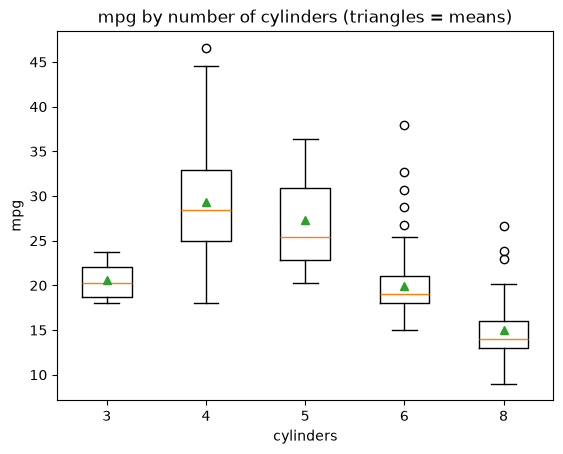

,count,mean,median,std
cylinders,,,,
3,4,20.55,20.25,2.56
4,199,29.28,28.40,5.67
5,3,27.37,25.40,8.23
6,83,19.97,19.00,3.83
8,103,14.96,14.00,2.84


In [2]:
#Q1a Count how many unique records there are for each cylinder type
print(auto["cylinders"].value_counts())

# Use a boxplot to show the mpg distribution for each cylinder count
levels = sorted(auto["cylinders"].unique())
plt.boxplot([auto.loc[auto["cylinders"] == c, "mpg"] for c in levels], tick_labels=levels, showmeans=True)
plt.xlabel("cylinders"); plt.ylabel("mpg")
plt.title("mpg by number of cylinders (triangles = means)")
plt.show()

# This table gives count/mean/median/std, which we will use in our answer for part c
auto.groupby("cylinders")["mpg"].agg(["count", "mean", "median", "std"]).round(2)


### Q1b+c: Create a new variable called cylinder rollup and create the same plot as above

In the exercise above, we can see that there are only 3 cars in the dataset with 5 cylinders and only 4 cars with 3 cylinders. For this reason, we are going to combine these categories with the 4 cylinder category to create a single category called < 6 cylinders. 

In [3]:
# Q1b - First, let's create this new rollup and verify we did it correctly by matching the counts
auto["cyl_rollup"] = np.select([auto["cylinders"] < 6, auto["cylinders"] == 6], ["<6", "6"], default="8")
auto["cyl_rollup"].value_counts()


cyl_rollup
<6    206
8     103
6      83
Name: count, dtype: int64

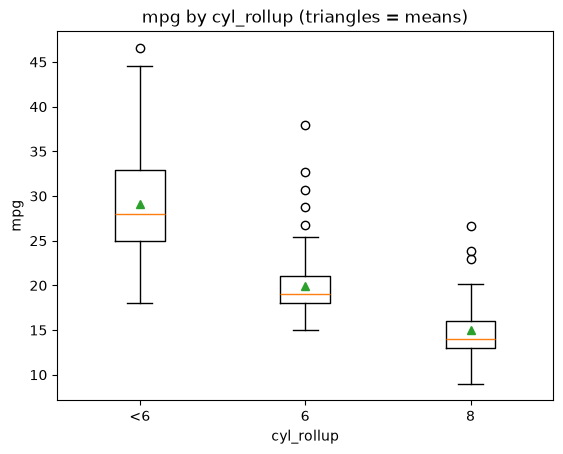

,count,mean,median,std
cyl_rollup,,,,
<6,206,29.09,28.0,5.77
6,83,19.97,19.0,3.83
8,103,14.96,14.0,2.84


In [4]:
#Q1c - Now let's plot this
roll_levels = ["<6", "6", "8"]
plt.boxplot([auto.loc[auto["cyl_rollup"] == c, "mpg"] for c in roll_levels], tick_labels=roll_levels, showmeans=True)
plt.xlabel("cyl_rollup"); plt.ylabel("mpg")
plt.title("mpg by cyl_rollup (triangles = means)")
plt.show()
auto.groupby("cyl_rollup")["mpg"].agg(["count", "mean", "median", "std"]).loc[roll_levels].round(2)

**Q1c:** Every group now has 80+ cars, and mpg drops from <6 (mean 29.1) to 6 (20.0) to 8 (15.0). The boxes (middle 50% of the cars) don't overlap. The <6 group is the most spread out, partly because it combines the 3-, 4-, and 5-cylinder cars. We saw from Q1a that 3-cylinder cars behave differently from the 4-cylinder cars (lower mpg) but there are only 4 of them.

### Q1d Exploring the variable "name" in the dataset

In [5]:
#Q1d - First, let's look at the unique values of this column in the dataset
print(auto["name"].head())
print("Unique names:", auto["name"].nunique(), "of", len(auto))

0    chevrolet chevelle malibu
1            buick skylark 320
2           plymouth satellite
3                amc rebel sst
4                  ford torino
Name: name, dtype: str
Unique names: 301 of 392


**Q1d:** "name" has 301 unique values across 392 cars so it almost uniquely identifies each vehicle. One-hot encoding it would add a column for almost every car, and we would add too much variance to the model, significantly overfitting to the current data.

### Q2a: Forward selection (numeric features only)

In [6]:
num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]
SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)   # same object for Q2a and Q2b

# The function below, sfs_features, does the following:
# 1. Creates a pipeline that uses the StandardScaler() on all variables 
# 2a. Does a sequential feature selection for k features using the KFold cv object defined above
# 2b. Note that the scoring uses "neg_root_mean_squared_error" as defined in the setup section
# 3. Returns a list of the selected features 

def sfs_features(k, direction="forward"):
    pipe = make_pipeline(
        StandardScaler(),
        SequentialFeatureSelector(LinearRegression(), n_features_to_select=k,
                                  direction=direction, cv=cv, scoring=SCORING),
    ).set_output(transform="pandas")
    return list(pipe.fit(X, y).get_feature_names_out())

# This loop executes the feature selection for each value of k from 1-4 and prints a list of features at each step
for k in range(1, 5):
    print(k, sfs_features(k))

1 ['weight']
2 ['weight', 'year']
3 ['horsepower', 'weight', 'year']
4 ['displacement', 'horsepower', 'weight', 'year']


### Q2b: Backward selection, k = 3

In [7]:
# This uses the same function as above, but passes "backward" as the direction of feature selection
bwd3 = sfs_features(3, "backward")
print("Backward:", bwd3)

Backward: ['horsepower', 'weight', 'year']


**Q2b:** The answer is: It depends on the random seed! Some of you might see that the two methods choose the same features at k=3, some of you might get different features. In the code above, you will see that if you change the SEED from 200 to 100, you will see that the answer is different. For 200, it should be the same. Weight and year are always chosen in both cases, and the third variable is one of horsepower, displacement, or acceleration. We'll explore this more in part c below. 

Regardless of which features you chose in this step, Forward and Backward Selection choosing the same features at k=3 does not guarantee the best 3-feature model. Both of these algorithms are greedy, so each step chooses to add or remove a single feature at a time based on what is already in the model. It does this by selecting the model with the lowest CV RMSE at each step.  

### Q2c: Correlations and VIFs

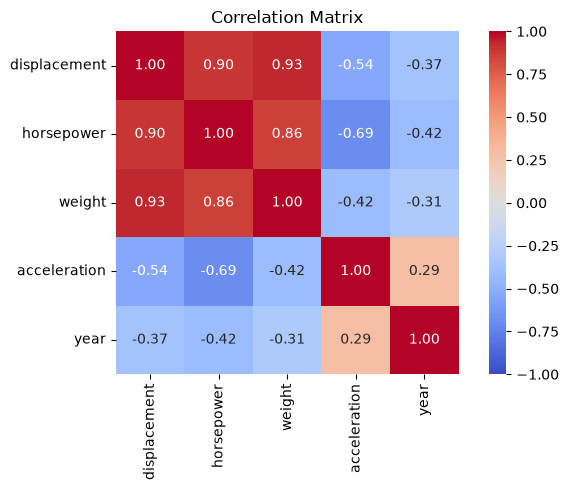

displacement    10.8
horsepower       9.3
weight          10.6
acceleration     2.6
year             1.2
dtype: float64

In [8]:
# Here, I am plotting the heatmap for all of the numeric variables in this dataset
plt.figure(figsize=(7, 5))
sns.heatmap(auto[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# Using statsmodels to calculate VIF.
X_const = sm.add_constant(auto[num])
pd.Series([variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
          index=num).round(1)

**Q2c:** displacement, horsepower, and weight are correlated at 0.86–0.93, with VIFs of about 9–11, so they carry largely the same information. 

Backward Selection starts with all five features and drops them one at a time, whereas Forward Selection starts with the single best predictor first (weight, according to what we saw above) and then adds other variables one at a time. Neither method checks for multicollinearity directly. Forward selection often picks the strongest member of the correlated group early, because it chooses the single most predictive feature in the first step. Backward selection starts with all of the correlated variables, and since each variable doesn't add much given the others, which ones are dropped can be arbitrary. 

In general, high VIFs can make the selected subset of features unstable. Once weight has been added to the model, a different CV split (or a slightly different sample) could swap displacement for horsepower, and the two methods can end up with different features. This is part of what we saw in Q2b. Different features were chosen based on the random seed (which impacted the CV split), and that is partially due to the multicollinearity in 3/5 features we looked at.  

In addition, as we have discussed at length, the coefficients of correlated features that are both selected are also hard to interpret. If all we care about is predictive accuracy, this is less important, but if care about interpretability, including multicollinear features at the start can be problematic. 

This is an example of why the approach of "just throw all the features in and ignore multicollinearity" isn't always the right approach. 

## Part 2: Cross-Validation Approaches

In this part of the lab, we are shifting to prediction and looking at cross-validation. Even though we saw above that displacement and weight are correlated, we are using both of them in this exercise. Let's assume, for this part of the assignment, that we did a Feature Selection process and chose displacement, weight, and year.

In [9]:
# Part 2 - Setting up the code to build models A and B with the Standard Scaler and One Hot Encoder

# We will use this models dictionary throughout this exercise. 
models = {
    "A": (["displacement", "weight", "year"], []),
    "B": (["displacement", "weight", "year"], ["cyl_rollup", "origin"]),
}

# This function constructs the column preprocessor and pipeline for the linear regression
def make_model(numeric, categorical):
    steps = [(StandardScaler(), numeric)]
    if categorical:
        steps.append((OneHotEncoder(drop="first"), categorical))
    return make_pipeline(make_column_transformer(*steps), LinearRegression())

Xa = auto[["displacement", "weight", "year", "cyl_rollup", "origin"]]
ya = auto["mpg"]

### Q1: Single 80/20 train/test split

In [10]:
# Q1a
# We are going to set the random seed prior to doing this exercise for repeatable results
# Note: You COULD use the same random seed as in Part 1, but is not necessary. 
SEED = 42
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=SEED)

rows = []
# This loop uses the models dictionary that we defined above. 
for name, (numeric, categorical) in models.items():
    m = make_model(numeric, categorical).fit(Xa_tr, ya_tr)
    rows.append({"model": name,
                 "train_rmse": root_mean_squared_error(ya_tr, m.predict(Xa_tr)),
                 "test_rmse": root_mean_squared_error(ya_te, m.predict(Xa_te))})
split_tbl = pd.DataFrame(rows).set_index("model")
split_tbl.round(3)

,train_rmse,test_rmse
model,,
A,3.460,3.261
B,3.226,3.089


**Q1b:** Model B has lower training RMSE and test RMSE, so from a single train/test split, Model B looks better. 

### Q2: Building Models A and B with 5-fold and 10-fold CV

In [11]:
# This function cv_scores, defined below, takes a model, number of splits, and seed as SEED as inputs
# It then creates a KFold cross validation object and returns the cross validation score for each model
def cv_scores(model, n_splits, seed=SEED):
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return -cross_val_score(model, Xa, ya, cv=folds, scoring=SCORING)

# Q2a, this is the loop that builds the model with 5 and 10-fold cross validation
for name, (numeric, categorical) in models.items():
    s5 = cv_scores(make_model(numeric, categorical), 5, seed=SEED)
    s10 = cv_scores(make_model(numeric, categorical), 10, seed=SEED)
    split_tbl.loc[name, "5fold_rmse"] = s5.mean()
    split_tbl.loc[name, "10fold_rmse"] = s10.mean()
    split_tbl.loc[name, "10fold_se"] = s10.std(ddof=1) / np.sqrt(10)
split_tbl.round(3)

,train_rmse,test_rmse,5fold_rmse,10fold_rmse,10fold_se
model,,,,,
A,3.460,3.261,3.422,3.391,0.194
B,3.226,3.089,3.235,3.205,0.203


**Q2b:** For the seed I chose (42) the test RMSE is actually lower than the training RMSE for a single split for both models, which is an artifact of how the data was split. Typically, we would not expect this, and this is why a single train/test split can be misleading. The 5fold CV RMSE is higher than the single train/test split (since we are averaging over every observation), and the 10fold RMSE is lower than the 5fold, which we'd expect because we are training on 90% of the data each time.  

**Q2c:** Model B still has the lowest RMSE, and we can trust this assertion more than we could with a single split. One item of note:

* In Chapter 6 of Introduction to Statistical Learning, at the end of section 6.1, the authors introduce the notion of the "one-standard-error" rule. It advises selecting the smallest model (e.g. the one with the fewest predictors) that is within one standard error of the model with the lowest RMSE. As they state: The rationale here is that if a set of models appear to be more or less equally good, then we might as well choose the simplest model." In the example above, the test RMSE for model B (10fold cross validation) is less than one standard error lower than the test RMSE for model A, indicating that Model A would be a better choice. That said, it just barely makes this cutoff (3.391-3.205 = 0.186, which is very close to 0.194) **You do not need to cite this one standard error rule in your explanation to get full credit, as we did not discuss this in class!**

### Q3: 100 random seeds

Now we want to repeat this process for 100 different random seeds, building this model for a single train-test split, and with 5 and 10 fold cross validation. 

In [12]:
# This looping, redoing the model calculation for each seed
# It is very similar to (though slightly modified) to the in-class notebook
rows = []
for seed in range(100):
    tr_X, te_X, tr_y, te_y = train_test_split(Xa, ya, test_size=0.2, random_state=seed)
    for name, (numeric, categorical) in models.items():
        model = make_model(numeric, categorical)
        fitted = model.fit(tr_X, tr_y)
        rows += [
            {"model": name, "method": "Train/test", "seed": seed,
             "rmse": root_mean_squared_error(te_y, fitted.predict(te_X))},
            {"model": name, "method": "5-fold", "seed": seed, "rmse": cv_scores(model, 5, seed).mean()},
            {"model": name, "method": "10-fold", "seed": seed, "rmse": cv_scores(model, 10, seed).mean()},
        ]
by_seed = pd.DataFrame(rows)

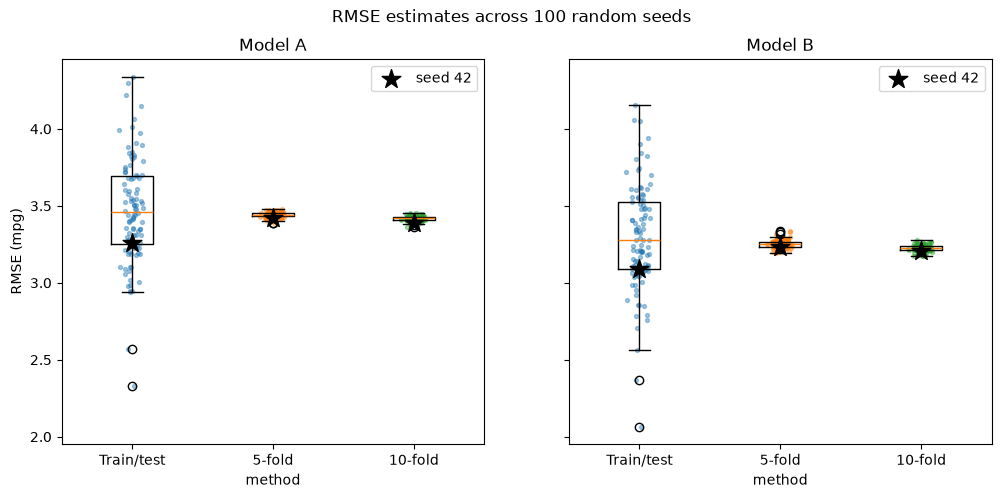

mean    std
method     model              
Train/test A      3.472  0.344
           B      3.292  0.349
5-fold     A      3.440  0.018
           B      3.252  0.027
10-fold    A      3.418  0.017
           B      3.225  0.022

In [13]:
# One facet per model, so each panel compares the three methods
# Note this is the part of the lab where you can use the same plot as our in class notebook. 
# I modified it a bit here
order = ["Train/test", "5-fold", "10-fold"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, name in zip(axes, models):
    sub = by_seed[by_seed["model"] == name]
    ax.boxplot([sub.loc[sub.method == m, "rmse"] for m in order], tick_labels=order)
    for i, m in enumerate(order, start=1):
        vals = sub.loc[sub.method == m, "rmse"]
        ax.scatter(np.random.default_rng(0).normal(i, 0.04, len(vals)), vals, s=8, alpha=0.4)
        ax.scatter(i, sub.loc[(sub.method == m) & (sub.seed == 42), "rmse"],
                   marker="*", s=200, color="black", zorder=3, label="seed 42" if i == 1 else None)
    ax.set(title=f"Model {name}", xlabel="method")
    ax.legend()
axes[0].set_ylabel("RMSE (mpg)")
fig.suptitle("RMSE estimates across 100 random seeds")
plt.show()

by_seed.groupby(["method", "model"])["rmse"].agg(["mean", "std"]).loc[order].round(3)

**Q3a:** Model B. As we can see from the plot and table above, the single train/test split estimates are very noisy (which we'd expect!), and the A and B boxes overlap heavily. The 5- and 10-fold estimates are tightly clustered (SD ≈ 0.02) and B has a lower RMSE. 

**Q3b:** This is a judgement call, whether or not to add the categorical variables, and either answer is defensible. You can get full credit for either answer, provided that you are thoughtful in your justification. 
- **Yes:** The improvement in the predictive accuracy of the model when adding the categorical variables is very consistent, particularly when we look at 5 and 10-fold cross validation.  
- **No:** The difference between the mean RMSE for both models is quite small for both 5 and 10-fold cross validation. It is only around 0.19 mpg, which is within the standard error we calculated above. If we do choose to include the categorical variables, one hot encoding adds four different coefficients to the model for the two categorical variables under consideration, which make the model harder to interpret. Depending on the use case, this additional complexity may not be worth it for minimal increase in predictive power. 

## Part 3: Polynomial and Spline Regression

In [14]:
#Q1 a-c: This is the code to fit three models using a train/test split. 
Xb = bike[["temp"]]
yb = bike["cnt"]

#Again, we are creating a new seed. (Not necessary, but also not required to use the same seed as previously)
SEED = 123
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=SEED)

def linear():
    return make_pipeline(LinearRegression())

def poly(d):
    return make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), LinearRegression())

def spline(k):
    return make_pipeline(SplineTransformer(degree=3, n_knots=k, knots="quantile"), LinearRegression())

bike_models = {"A: linear": LinearRegression(), "B: poly 9": poly(9), "C: spline 7 knots": spline(7)}
for m in bike_models.values():
    m.fit(Xb_tr, yb_tr)

### Q1d: Fitted curves

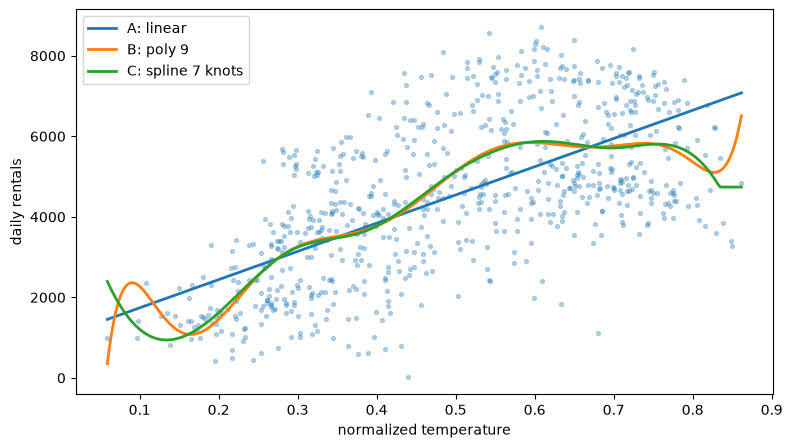

In [15]:
grid = pd.DataFrame({"temp": np.linspace(Xb["temp"].min(), Xb["temp"].max(), 300)})
plt.figure(figsize=(9, 5))
plt.scatter(bike["temp"], bike["cnt"], s=8, alpha=0.3)
for name, m in bike_models.items():
    plt.plot(grid["temp"], m.predict(grid), lw=2, label=name)
plt.xlabel("normalized temperature"); plt.ylabel("daily rentals"); plt.legend()
plt.show()

**Q1d** Observations
* Looking just at the scatter in temperature vs count of daily bike rentals, there is a clear curvature that we can observe. 
* The fit of the linear model clearly misses this curvature. 
* The polynomial and spline regressions both capture curvature in the data with some variation, though there is a fair amount of overlap in the curves from around x=0.2-0.7. The fits start to diverge more at the edge of the x-values.  

**Note** The exact shape of the curve will depend on the random seed, but the above observations should still be true. Try editing the SEED value above and seeing what happens!

### Q2: Training and test RMSE

In [16]:
#Q2 - This creates a dataframe to calculate rmse for on the training and testing data for each model
rmse_tbl = pd.DataFrame({
    name: {"train_rmse": root_mean_squared_error(yb_tr, m.predict(Xb_tr)),
           "test_rmse": root_mean_squared_error(yb_te, m.predict(Xb_te))}
    for name, m in bike_models.items()
}).T
rmse_tbl["test_minus_train"] = rmse_tbl["test_rmse"] - rmse_tbl["train_rmse"]
rmse_tbl.round(2)

,train_rmse,test_rmse,test_minus_train
A: linear,1477.19,1628.52,151.33
B: poly 9,1386.75,1526.17,139.42
C: spline 7 knots,1390.46,1503.04,112.58


**Q2a-c:**

- **(a)** Smallest training RMSE: degree-9 polynomial (though only by a small amount). Smallest test RMSE: spline.
- **(b)** No, decreasing the training error does not imply decreasing the testing error. For example, the polynomial has the lowest training RMSE but does not have the lowest test RMSE. This is because training error can continue decreasing as flexibility increases, but test error can increase if the model starts overfitting to sample-specific data. 
- **(c)** Underfitting occurs when a model is too restrictive to capture important structure in the data. The simple Linear Regression in this example underfits the data because it is too restrictive to capture the curvature. It has the highest training and testing RMSE. Looking at the table above, the polynomial overfits the data more than the spline, as it has the lowest training RMSE but not the lowest test RMSE. 

**Note** The values for train and test RMSE are dependent on what you choose for your random number generator seed. The values reported are for the random seed used for this notebook (123), and your values might be slightly different, leading you to draw different conclusions around how the polynomial and spline regressions overfit the data (or don't). To more precisely assess these models, we would want to repeat this analysis multiple times with a number of different train/test splits, and get the RMSE spread for each model. I've done this below. **You do not need to repeat this analysis with 100 different seeds to get full credit**

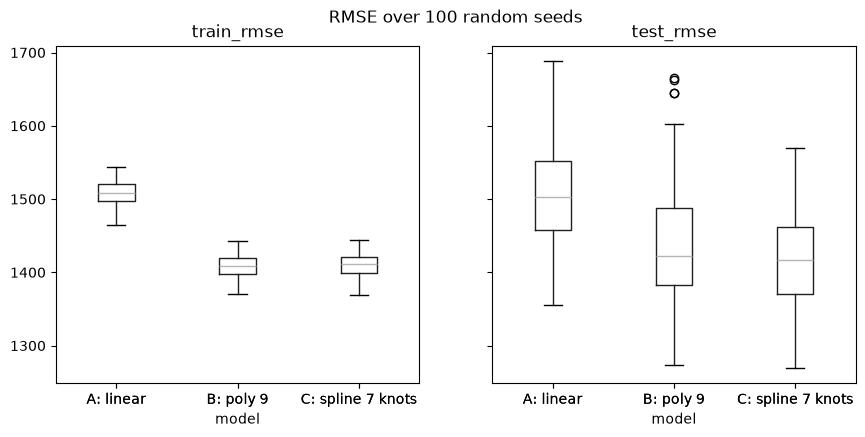

In [17]:
# In this cell, I am taking the code where I built the models above, and running them 100 times, calculating the train and test RMSE each time. 
# Then I use a boxplot to look at the spread of values. 
rows = []
for seed in range(100):
    tr_X, te_X, tr_y, te_y = train_test_split(Xb, yb, test_size=0.2, random_state=seed)
    for name, m in bike_models.items():
        fit = clone(m).fit(tr_X, tr_y)
        rows.append({"model": name,
                     "train_rmse": root_mean_squared_error(tr_y, fit.predict(tr_X)),
                     "test_rmse": root_mean_squared_error(te_y, fit.predict(te_X))})
seed_tbl = pd.DataFrame(rows)

means = seed_tbl.groupby("model").mean()
sds = seed_tbl.groupby("model").std()
seed_tbl.boxplot(column=["train_rmse", "test_rmse"], by="model", figsize=(10, 4.5), grid=False)
plt.suptitle("RMSE over 100 random seeds")
plt.show()

In [18]:
# The table below looks at the mean rmse for both training and testing across 100 different seeds. 
seed_tbl.groupby("model").mean()

,train_rmse,test_rmse
model,,
A: linear,1507.904503,1505.963421
B: poly 9,1408.327044,1439.212156
C: spline 7 knots,1410.185226,1416.139703


**Q2c continued** The plots and table above give us more context in which to answer the above question about overfitting and underfitting.
* The linear model has the highest training and testing RMSE, indicating that the linear model does not do a good job of capturing all of the variance in the data.
* The 9-degree polynomial has the lowest training RMSE, but not the lowest test RMSE, whereas the test RMSE for the spline model is only just slightly higher than the train RMSE. This indicates that the polynomial is overfitting more than the spline. 
* We can also see more outliers (the circles on the plot) for the polynomial, indcating that for certain random seeds, the test RMSE was quite high, a hallmark of overfitting. 

These are the same conclusions I drew above for one train/test split, but only because of the random seed I chose. This is part of why doing a single train/test split is usually not sufficient to get a handle on what your model is doing. We'll see this below with cross validation as well. 

### Q3: 5-fold CV

In [19]:
SEED = 123
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
rmse_tbl["5fold_rmse"] = [
    -cross_val_score(clone(m), Xb, yb, cv=cv5, scoring=SCORING).mean() for m in bike_models.values()
]
rmse_tbl.round(2)

,train_rmse,test_rmse,test_minus_train,5fold_rmse
A: linear,1477.19,1628.52,151.33,1512.54
B: poly 9,1386.75,1526.17,139.42,1453.78
C: spline 7 knots,1390.46,1503.04,112.58,1425.51


**Q3 answer:** CV gives us a similar assessment to the one we made above. 

It ranks the models
1. spline (≈ 1425)
2. polynomial (≈ 1453)
3. linear model (≈ 1513). 

It agrees that the line underfits and the spline is best, and also demonstrates why cross-validation helps give us more confidence in our RMSE values. Through cross-validation, every day is used as test data in one fold and the estimate doesn't hinge on one randomly chosen set of ~147 days. The differences between the polynomial and spline are still fairly small--you could likely choose either to fit this data. 

## Part 4: The Bias-Variance Tradeoff

In this part of the lab, we are going to use bootstrapping to simulate how our predictions would change if we had a different training sample. 

### Q1a: Bootstrap at temp = 0.60

Uses the same 80/20 split and the same three models as Part 3.

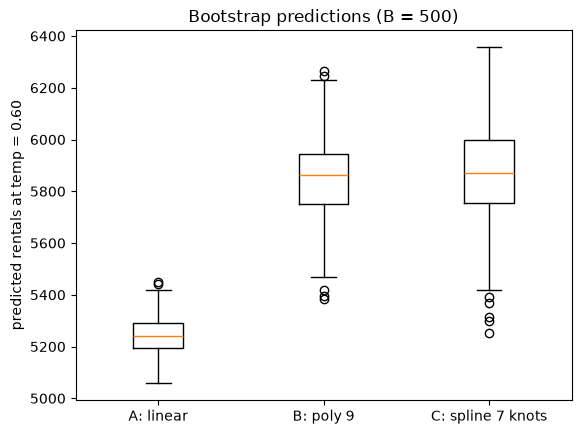

,mean,std
model,,
A: linear,5242.8,69.9
B: poly 9,5852.7,153.9
C: spline 7 knots,5874.4,185.7


In [20]:
B = 500
rng = np.random.default_rng(SEED)
x_new = pd.DataFrame({"temp": [0.60]})

boot = []
for b in range(B):
    idx = rng.choice(len(Xb_tr), size=len(Xb_tr), replace=True)
    for name, m in bike_models.items():
        pred = clone(m).fit(Xb_tr.iloc[idx], yb_tr.iloc[idx]).predict(x_new)[0]
        boot.append({"model": name, "prediction": pred})
boot = pd.DataFrame(boot)

names = list(bike_models)
plt.boxplot([boot.loc[boot["model"] == n, "prediction"] for n in names], tick_labels=names)
plt.ylabel("predicted rentals at temp = 0.60")
plt.title("Bootstrap predictions (B = 500)")
plt.show()

boot.groupby("model")["prediction"].agg(["mean", "std"]).round(1)

**Q1a:** The linear model is the most stable because it has the lowest standard deviation. You can see this both visually in the plot and by viewing means and standard deviations in the table.  The 7-knot spline is the most variable with the highest standard deviation, but overlaps significantly with the polynomial. 

### Q1b Prediction variability 

Remember that variance is error introduced due to sensitivity to the training data. Here, we simulated 500 different samples of training data and looked at model predictions at a single point. The more flexible models (polynomial, splines) have larger standard deviations, indicating greater variance in predictions at temp=0.60. This indicates that the more flexible models are also more variable. 

### Q1c

More generally, if a model fits training observations very well, but has large variance in out of sample predictions, the model is unlikely to generalize well, because it is very sensitive to the training data.

### Q2 Putting Everything Together. 

**Q2a:**
* The linear model has the highest bias among the three models. It does not capture the curvature in the data and consistently has the highest train, test, and CV RMSE. It also has the lowest variance, which is demonstrated by the bootstrapping we did. The predicted values at temp=0.60 have the lowest standard deviation for the linear model. 
* Both the 9-degree polynomial and 7-knot spline have lower bias than the linear model and capture more curvature in the data. Both models also have higher variance than the linear model, as demonstrated by the spread in predicted values at temp=0.60, indicating that both of these models are more sensitive to training data than the linear model. The polynomial model overfits a bit more than the spline. The spline has the lowest test RMSE of the three models, indicating that it performs better on unseen data. 

**Q2b** We should generally NOT choose the model with the smallest training RMSE. Training RMSE always rewards flexibility/complexity, because a flexible model can fit the training data more exactly. The flip side is that flexibility can cause overfitting, because some of the variance is due to noise in the training sample and may not be present more generally. In this particular example, the degree-9 polynomial had the lowest training RMSE but not the lowest test RMSE, indicating that it likely overfit the training data more than the spline, and we traded a reduction in bias for too much variance. 